In [1]:

import sys
import subprocess
from pathlib import Path
from importlib.metadata import version
import torch

REPO = Path("/kaggle/working/resilientinspect-ai")

if (REPO / ".git").is_dir():
    subprocess.run(
        ["git", "-C", str(REPO), "pull", "--ff-only"],
        check=True
    )
else:
    subprocess.run([
        "git", "clone",
        "https://github.com/nouhabenkhelil/resilientinspect-ai.git",
        str(REPO)
    ], check=True)

commit = subprocess.check_output(
    ["git", "-C", str(REPO), "rev-parse", "HEAD"],
    text=True
).strip()

assert commit.startswith("81920fb"), f"Commit inattendu : {commit}"

assert torch.cuda.is_available(), "Activer GPU T4"
torch_before = torch.__version__

constraints = Path("/kaggle/working/torch_constraints.txt")
constraints.write_text(f"torch=={torch_before}\n")

subprocess.run([
    sys.executable, "-m", "pip", "install",
    "-q", "-e", f"{REPO}[train,dev]",
    "-c", str(constraints)
], check=True)

assert version("torch") == torch_before

# Éviter les problèmes d'import après installation
if str(REPO / "src") not in sys.path:
    sys.path.insert(0, str(REPO / "src"))

print("Python :", sys.version.split()[0])
print("PyTorch :", torch.__version__)
print("GPU :", torch.cuda.get_device_name(0))
print("Mémoire GPU totale (Gio) :", round(
    torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
))
print("Commit :", commit[:10])


Cloning into '/kaggle/working/resilientinspect-ai'...
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
bigframes 2.51.0 requires google-cloud-bigquery-storage<3.0.0,>=2.30.0, which is not installed.
ydata-profiling 4.18.4 requires matplotlib<=3.10,>=3.5, but you have matplotlib 3.10.8 which is incompatible.


Python : 3.13.16
PyTorch : 2.11.0+cu130
GPU : Tesla T4
Mémoire GPU totale (Gio) : 14.56
Commit : 81920fb281


In [2]:
from pathlib import Path
import hashlib
import subprocess
import sys

# Projet GitHub
REPO = Path("/kaggle/working/resilientinspect-ai")

# Localiser le dataset MVTec AD
matches = list(Path("/kaggle/input").rglob("bottle/train/good"))

assert len(matches) == 1, f"Dataset introuvable ou ambigu : {matches}"

DATA_ROOT = matches[0].parents[2]

# Retrouver les manifestes
MANIFEST = REPO / "data/manifests/manifest.csv"

if not MANIFEST.exists():
    subprocess.run([
        sys.executable,
        "-m", "resilientinspect.data.prepare",
        "--root", str(DATA_ROOT),
        "--output-dir", str(MANIFEST.parent),
        "--report", "/kaggle/working/a1_preparation.json"
    ], cwd=REPO, check=True)

# Vérifier les mêmes splits que B0
EXPECTED_SHA = "13f55c7cf7c87a3e3739e24920bb0d85cc96a39a00e30d277ddfaa1832b84522"

actual_sha = hashlib.sha256(MANIFEST.read_bytes()).hexdigest()

assert actual_sha == EXPECTED_SHA, "Attention : les splits sont différents de B0 !"

A1_ROOT = Path("/kaggle/working/a1_runs")

print("Dataset :", DATA_ROOT)
print("Manifest :", MANIFEST)
print("SHA256 :", actual_sha)
print("Préparation A1 réussie !")

{
  "counts": {
    "bottle": {
      "train": 167,
      "val": 42,
      "test": 83,
      "test_good": 20,
      "test_anomalous": 63
    },
    "hazelnut": {
      "train": 312,
      "val": 79,
      "test": 110,
      "test_good": 40,
      "test_anomalous": 70
    },
    "leather": {
      "train": 196,
      "val": 49,
      "test": 124,
      "test_good": 32,
      "test_anomalous": 92
    }
  },
  "totals": {
    "train": 675,
    "val": 170,
    "test": 317
  },
  "manifest_sha256": {
    "manifest.csv": "13f55c7cf7c87a3e3739e24920bb0d85cc96a39a00e30d277ddfaa1832b84522",
    "train.csv": "781b1143fee9eab14f871f4f6335a94f9832c8bb0f13efbb8c40f54d3eadc5d4",
    "val.csv": "08f10f23fa04a531188684a46ae2578c9337e8c81f6c3c20aaf1b3c20b963092",
    "test.csv": "10b4d50e66d9c98cfd53a55b304be4fe150ad4e1eaf7e7a99c1c019d793d30ac"
  }
}
Dataset : /kaggle/input/datasets/nouhebenkhelil/resilientinspect-mvtec3
Manifest : /kaggle/working/resilientinspect-ai/data/manifests/manifest.csv
SHA256 

In [3]:

# Tests de l'architecture, SSIM, augmentations et entraînement
subprocess.run([
    sys.executable, "-m", "pytest",
    "tests/test_improved.py", "-q"
], cwd=REPO, check=True)

A1_ROOT = Path("/kaggle/working/a1_runs")

# Smoke test CUDA sur Bottle
subprocess.run([
    sys.executable, "-m",
    "resilientinspect.training.train_ae",
    "--config", str(REPO / "configs/train_ae_a1.yaml"),
    "--root", str(DATA_ROOT),
    "--manifest", str(MANIFEST),
    "--category", "bottle",
    "--device", "cuda",
    "--output-dir", str(A1_ROOT),
    "--smoke"
], cwd=REPO, check=True)

print("Smoke test A1 GPU réussi.")


..................................................                       [100%]
50 passed in 26.78s


2026/11/08 20:56:28 INFO mlflow.store.db.utils: Creating initial MLflow database tables...
2026/11/08 20:56:28 INFO mlflow.store.db.utils: Updating database tables


{"category": "bottle", "scope": "smoke", "epoch": 1, "train_loss": 0.3263108879327774, "val_loss": 0.320475310087204, "train_images": 4, "val_images": 4, "train_batches": 2, "val_batches": 2, "train_l1_loss": 0.30198635160923004, "train_ssim_loss": 0.42360900342464447, "val_l1_loss": 0.33403265476226807, "val_ssim_loss": 0.26624587178230286}
{
  "run_id": "817b32f525d842fbab83d5bb4d14da8b",
  "run_dir": "/kaggle/working/a1_runs/bottle/smoke_817b32f525d842fbab83d5bb4d14da8b",
  "category": "bottle",
  "scope": "smoke",
  "best_epoch": 1,
  "best_val_loss": 0.320475310087204
}
Smoke test A1 GPU réussi.


In [4]:

# Tests de l'architecture, SSIM, augmentations et entraînement
subprocess.run([
    sys.executable, "-m", "pytest",
    "tests/test_improved.py", "-q"
], cwd=REPO, check=True)

A1_ROOT = Path("/kaggle/working/a1_runs")

# Smoke test CUDA sur Bottle
subprocess.run([
    sys.executable, "-m",
    "resilientinspect.training.train_ae",
    "--config", str(REPO / "configs/train_ae_a1.yaml"),
    "--root", str(DATA_ROOT),
    "--manifest", str(MANIFEST),
    "--category", "bottle",
    "--device", "cuda",
    "--output-dir", str(A1_ROOT),
    "--smoke"
], cwd=REPO, check=True)

print("Smoke test A1 GPU réussi.")


..................................................                       [100%]
50 passed in 16.35s
{"category": "bottle", "scope": "smoke", "epoch": 1, "train_loss": 0.3263108879327774, "val_loss": 0.320475310087204, "train_images": 4, "val_images": 4, "train_batches": 2, "val_batches": 2, "train_l1_loss": 0.30198635160923004, "train_ssim_loss": 0.42360900342464447, "val_l1_loss": 0.33403265476226807, "val_ssim_loss": 0.26624587178230286}
{
  "run_id": "b2756897ce6f425c9e7e6096a9b10c54",
  "run_dir": "/kaggle/working/a1_runs/bottle/smoke_b2756897ce6f425c9e7e6096a9b10c54",
  "category": "bottle",
  "scope": "smoke",
  "best_epoch": 1,
  "best_val_loss": 0.320475310087204
}
Smoke test A1 GPU réussi.


In [5]:

import json
import shutil

def train_a1(category):
    assert category in ("bottle", "hazelnut", "leather")

    completed = []
    for summary_path in (A1_ROOT / category).glob("full_*/summary.json"):
        summary = json.loads(summary_path.read_text())
        if (summary.get("status") == "completed"
            and summary.get("variant") == "A1"
            and (summary_path.parent / "best.pt").exists()):
            completed.append(summary_path)

    if completed:
        assert len(completed) == 1, "Plusieurs runs complets : revue nécessaire"
        print(category, ": déjà entraîné, pas de relance")
        return

    subprocess.run([
        sys.executable, "-m",
        "resilientinspect.training.train_ae",
        "--config", str(REPO / "configs/train_ae_a1.yaml"),
        "--root", str(DATA_ROOT),
        "--manifest", str(MANIFEST),
        "--category", category,
        "--device", "cuda",
        "--output-dir", str(A1_ROOT)
    ], cwd=REPO, check=True)

    print("A1 terminé :", category)

def backup_a1():
    archive = shutil.make_archive(
        "/kaggle/working/A1_ResilientInspect_backup",
        "zip",
        root_dir="/kaggle/working",
        base_dir="a1_runs"
    )
    print("Sauvegarde :", archive)


In [6]:
train_a1("bottle")
backup_a1()

{"category": "bottle", "scope": "full", "epoch": 1, "train_loss": 0.1804967911657459, "val_loss": 0.4141745013850076, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3, "train_l1_loss": 0.16391810948798757, "train_ssim_loss": 0.24681152644271623, "val_l1_loss": 0.4456439429805392, "val_ssim_loss": 0.28829673926035565}
{"category": "bottle", "scope": "full", "epoch": 2, "train_loss": 0.06126049897092545, "val_loss": 0.13965449659597307, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3, "train_l1_loss": 0.043361425734387185, "train_ssim_loss": 0.13285678910638044, "val_l1_loss": 0.11751228996685573, "val_ssim_loss": 0.2282232968580155}
{"category": "bottle", "scope": "full", "epoch": 3, "train_loss": 0.04810168792655368, "val_loss": 0.07126589438744954, "train_images": 167, "val_images": 42, "train_batches": 11, "val_batches": 3, "train_l1_loss": 0.032516555470263886, "train_ssim_loss": 0.11044221545407872, "val_l1_loss": 0.051290963

In [7]:
train_a1("hazelnut")
backup_a1()

{"category": "hazelnut", "scope": "full", "epoch": 1, "train_loss": 0.09263646005628964, "val_loss": 0.053710570063772084, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5, "train_l1_loss": 0.08582726837350772, "train_ssim_loss": 0.11987322492477222, "val_l1_loss": 0.04931545832866355, "val_ssim_loss": 0.07129100945931446}
{"category": "hazelnut", "scope": "full", "epoch": 2, "train_loss": 0.028375991882804114, "val_loss": 0.04145448966116845, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5, "train_l1_loss": 0.021662459589349918, "train_ssim_loss": 0.055230119289496005, "val_l1_loss": 0.03445234201565574, "val_ssim_loss": 0.06946307571628425}
{"category": "hazelnut", "scope": "full", "epoch": 3, "train_loss": 0.026369827727858838, "val_loss": 0.030973061966367916, "train_images": 312, "val_images": 79, "train_batches": 20, "val_batches": 5, "train_l1_loss": 0.020054287921923857, "train_ssim_loss": 0.0516319840382307, "val_l1_loss

In [8]:
train_a1("leather")
backup_a1()

{"category": "leather", "scope": "full", "epoch": 1, "train_loss": 0.10119166833405592, "val_loss": 0.062275381112585265, "train_images": 196, "val_images": 49, "train_batches": 13, "val_batches": 4, "train_l1_loss": 0.07491372411652487, "train_ssim_loss": 0.20630341646622638, "val_l1_loss": 0.03661125297753178, "val_ssim_loss": 0.16493189456511517}
{"category": "leather", "scope": "full", "epoch": 2, "train_loss": 0.05274483774389539, "val_loss": 0.08373672256664354, "train_images": 196, "val_images": 49, "train_batches": 13, "val_batches": 4, "train_l1_loss": 0.025898303418439263, "train_ssim_loss": 0.16013097580598326, "val_l1_loss": 0.062152632493145614, "val_ssim_loss": 0.17007307799494997}
{"category": "leather", "scope": "full", "epoch": 3, "train_loss": 0.051284785021324546, "val_loss": 0.05475893738318463, "train_images": 196, "val_images": 49, "train_batches": 13, "val_batches": 4, "train_l1_loss": 0.02463068090835396, "train_ssim_loss": 0.15790120071294356, "val_l1_loss": 0.


Courbe : bottle


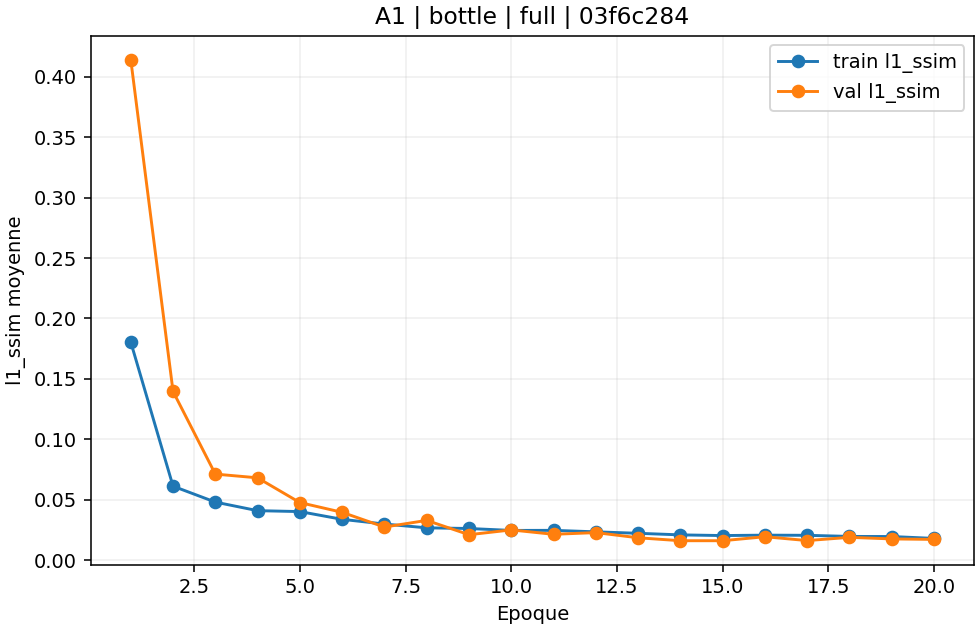


Courbe : hazelnut


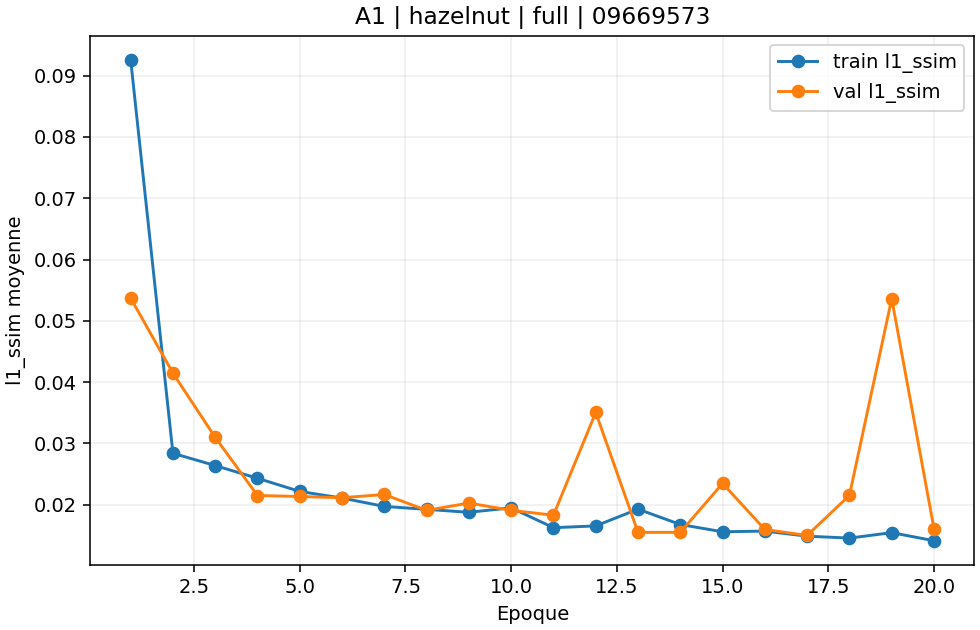


Courbe : leather


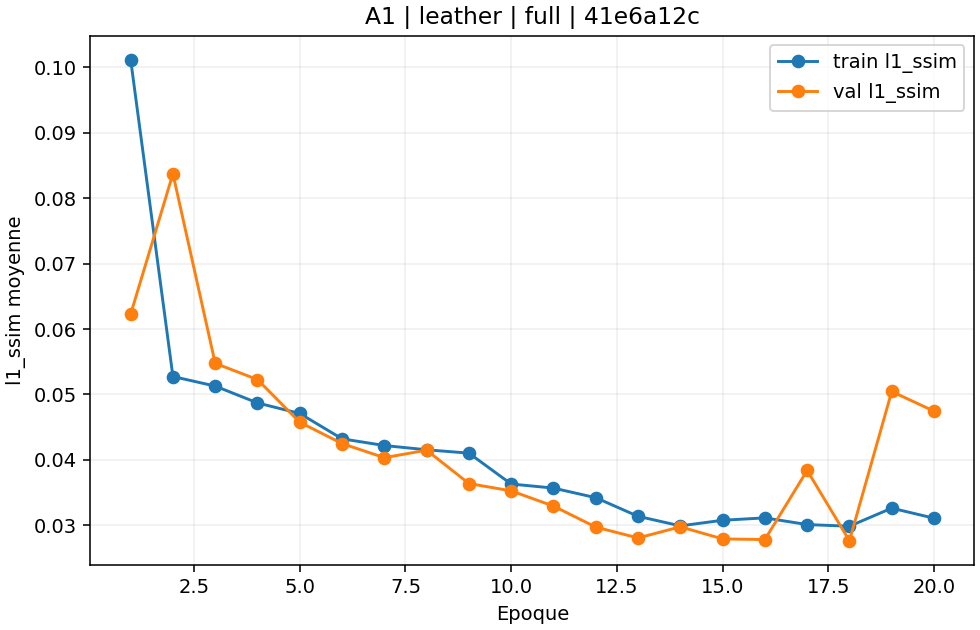

,categorie,epoques,best_epoch,val_loss_composite,val_L1
0,bottle,20,15,0.016155,0.011754
1,hazelnut,20,17,0.014966,0.011730
2,leather,20,18,0.027650,0.015471


In [9]:

import pandas as pd
from IPython.display import display, Image

results = []

for category in ["bottle", "hazelnut", "leather"]:
    files = list((A1_ROOT / category).glob("full_*/summary.json"))
    assert len(files) == 1, f"{category}: run manquant ou ambigu"

    summary = json.loads(files[0].read_text())
    assert summary["status"] == "completed"
    assert summary["variant"] == "A1"
    assert summary["test_used"] is False

    best = summary["best_epoch"]
    best_row = next(
        row for row in summary["history"]
        if row["epoch"] == best
    )

    results.append({
        "categorie": category,
        "epoques": summary["epochs_completed"],
        "best_epoch": best,
        "val_loss_composite": summary["best_val_loss"],
        "val_L1": best_row["val_l1_loss"]
    })

    print("\nCourbe :", category)
    display(Image(filename=str(
        files[0].parent / "loss_curves.png"
    )))

df = pd.DataFrame(results)
display(df)


In [10]:
import zipfile

archive = Path("/kaggle/working/A1_ResilientInspect_backup.zip")
assert archive.is_file()

with zipfile.ZipFile(archive) as z:
    checkpoints = [
        name for name in z.namelist()
        if name.endswith("best.pt")
        and "/full_" in name
        and "/mlartifacts/" not in name
    ]

print("Checkpoints complets :", checkpoints)
assert len(checkpoints) == 3
print("Archive prête :", archive)

Checkpoints complets : ['a1_runs/bottle/full_03f6c284b0164105bf364181695ce3b5/best.pt', 'a1_runs/hazelnut/full_0966957370a14cdda9d65a15e54cbaa5/best.pt', 'a1_runs/leather/full_41e6a12c4b4942b6b7d6dc9e1ea3720a/best.pt']
Archive prête : /kaggle/working/A1_ResilientInspect_backup.zip
